# M4 — Focal Tversky loss with the M2 Siamese U-Net

M4 uses the M2 architecture and replaces its BCE + Dice objective with Focal Tversky Loss. The loss weights false positives and false negatives separately; this run uses `alpha=0.6`, `beta=0.4` and `gamma=1.33`.

The architecture and data pipeline are otherwise retained from M2. The purpose is to measure the effect of the loss-function change, including any change in the precision–recall balance.

**Dataset split:** 445 training, 64 validation and 128 test image pairs. **Input size:** 128 × 128.

## M4 experimental change: Focal Tversky Loss

The M2 architecture is retained; only the loss function is changed. M2 uses Binary Cross-Entropy plus Dice Loss, while M4 uses Focal Tversky Loss.

For each image, the implementation calculates true positives, false positives and false negatives, then computes the Tversky index:

\[
TI=\frac{TP+\epsilon}{TP+\alpha FP+\beta FN+\epsilon}
\qquad
L_{FT}=(1-TI)^\gamma
\]

In this notebook, `alpha=0.6` weights false positives, `beta=0.4` weights false negatives and `gamma=1.33`. The per-image loss values are averaged across the batch.

## 1. Connect Google Drive and set the dataset location

Mount Google Drive, then set `DATASET_ROOT` to the directory containing the `train`, `val` and `test` folders. If the validation folder is named `valid`, update the corresponding entry in `SPLITS`.

In [1]:
from google.colab import drive
drive.mount('/content/drive')

# EDIT THIS to the directory containing train/, val/, and test/
DATASET_ROOT = "/content/drive/MyDrive/LEVIR-CD/LEVIR CD"

# Expected subfolder names
SPLITS = {
    "train": "train",
    "val": "val",
    "test": "test",
}

IMG_SIZE = 128
BATCH_SIZE = 4
SEED = 42

import os
os.makedirs("/content/m4_checkpoints", exist_ok=True)

for split_name, folder in SPLITS.items():
    split_path = os.path.join(DATASET_ROOT, folder)
    assert os.path.isdir(split_path), f"Missing split folder: {split_path}"

print("Dataset root:", DATASET_ROOT)
print("GPU devices:", __import__("tensorflow").config.list_physical_devices("GPU"))

Mounted at /content/drive
Dataset root: /content/drive/MyDrive/LEVIR-CD/LEVIR CD
GPU devices: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


## 2. Imports and reproducibility

This section imports the libraries used for image loading, model construction, training and evaluation. The random seeds and runtime settings are defined here so the experiment can be repeated with the same configuration.

In [2]:
import os
import random
from pathlib import Path
from collections import Counter

import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf

from tensorflow.keras import layers, models
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, confusion_matrix
)

random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

# Avoid TensorFlow reserving all GPU memory at startup.
for gpu in tf.config.list_physical_devices("GPU"):
    try:
        tf.config.experimental.set_memory_growth(gpu, True)
    except RuntimeError:
        pass

print("TensorFlow:", tf.__version__)
print("GPU:", tf.config.list_physical_devices("GPU"))

TensorFlow: 2.21.0
GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


## 3. Match the before, after and label files

Image pairs are matched by filename stem across the `A`, `B` and `label` folders. The checks stop execution if a sample is missing from any folder, preventing unrelated files from being paired by list position.

In [3]:
IMAGE_EXTENSIONS = {".png", ".jpg", ".jpeg", ".tif", ".tiff"}

def index_images(folder):
    folder = Path(folder)
    files = [
        p for p in folder.iterdir()
        if p.is_file() and p.suffix.lower() in IMAGE_EXTENSIONS
    ]
    indexed = {}
    for path in files:
        key = path.stem
        if key in indexed:
            raise ValueError(f"Duplicate filename stem '{key}' in {folder}")
        indexed[key] = str(path)
    return indexed

def build_pairs(split_name):
    split_dir = os.path.join(DATASET_ROOT, SPLITS[split_name])
    a_map = index_images(os.path.join(split_dir, "A"))
    b_map = index_images(os.path.join(split_dir, "B"))
    y_map = index_images(os.path.join(split_dir, "label"))

    ids_a, ids_b, ids_y = set(a_map), set(b_map), set(y_map)
    if not (ids_a == ids_b == ids_y):
        raise ValueError(
            f"Filename mismatch in {split_name}: "
            f"A-only={sorted(ids_a-ids_b)[:5]}, "
            f"B-only={sorted(ids_b-ids_a)[:5]}, "
            f"label-missing={sorted(ids_a-ids_y)[:5]}, "
            f"label-only={sorted(ids_y-ids_a)[:5]}"
        )

    sample_ids = sorted(ids_a)
    pairs = [(a_map[k], b_map[k], y_map[k], k) for k in sample_ids]
    print(f"{split_name}: {len(pairs)} verified pairs")
    return pairs

train_pairs = build_pairs("train")
val_pairs = build_pairs("val")
test_pairs = build_pairs("test")

expected_counts = {"train": 445, "val": 64, "test": 128}
actual_counts = {
    "train": len(train_pairs),
    "val": len(val_pairs),
    "test": len(test_pairs),
}
print("Actual counts:", actual_counts)
for split, expected in expected_counts.items():
    if actual_counts[split] != expected:
        print(f"WARNING: {split} has {actual_counts[split]} pairs; "
              f"Kaggle description says {expected}. Check folder contents.")

train: 445 verified pairs
val: 64 verified pairs
test: 128 verified pairs
Actual counts: {'train': 445, 'val': 64, 'test': 128}


## 4. Load and preprocess the image pairs

The before and after images are converted to RGB and resized using area interpolation. Label masks use nearest-neighbour interpolation to preserve their binary values. ResNet50 preprocessing is applied in the input pipeline using the expected 0–255 pixel scale.

In [4]:
def read_rgb_image(path):
    image = cv2.imread(path, cv2.IMREAD_COLOR)
    if image is None:
        raise ValueError(f"Could not read image: {path}")
    image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
    image = cv2.resize(
        image, (IMG_SIZE, IMG_SIZE),
        interpolation=cv2.INTER_AREA
    )
    return image.astype(np.uint8)

def read_binary_mask(path):
    mask = cv2.imread(path, cv2.IMREAD_GRAYSCALE)
    if mask is None:
        raise ValueError(f"Could not read mask: {path}")
    mask = cv2.resize(
        mask, (IMG_SIZE, IMG_SIZE),
        interpolation=cv2.INTER_NEAREST
    )
    # LEVIR-CD masks are binary (typically 0 and 255).
    # Any non-zero label is treated as changed.
    mask = (mask > 0).astype(np.float32)
    return mask[..., np.newaxis]

def load_split(pairs, split_name):
    images_a, images_b, masks = [], [], []
    for path_a, path_b, path_mask, sample_id in pairs:
        images_a.append(read_rgb_image(path_a))
        images_b.append(read_rgb_image(path_b))
        masks.append(read_binary_mask(path_mask))

    X_a = np.stack(images_a).astype(np.uint8)
    X_b = np.stack(images_b).astype(np.uint8)
    Y = np.stack(masks).astype(np.float32)

    print(
        f"{split_name}: A={X_a.shape}, B={X_b.shape}, "
        f"mask={Y.shape}, mask values={np.unique(Y)}"
    )
    return X_a, X_b, Y

X1_train, X2_train, y_train = load_split(train_pairs, "train")
X1_val, X2_val, y_val = load_split(val_pairs, "validation")

# Test files are deliberately not loaded/evaluated until final testing.
print("Test pairs reserved:", len(test_pairs))

train: A=(445, 128, 128, 3), B=(445, 128, 128, 3), mask=(445, 128, 128, 1), mask values=[0. 1.]
validation: A=(64, 128, 128, 3), B=(64, 128, 128, 3), mask=(64, 128, 128, 1), mask values=[0. 1.]
Test pairs reserved: 128


## 5. Check sample alignment

The plots below show examples from the two dates and their reference change masks. Check that all three images refer to the same scene and that the mask marks the expected changed regions.

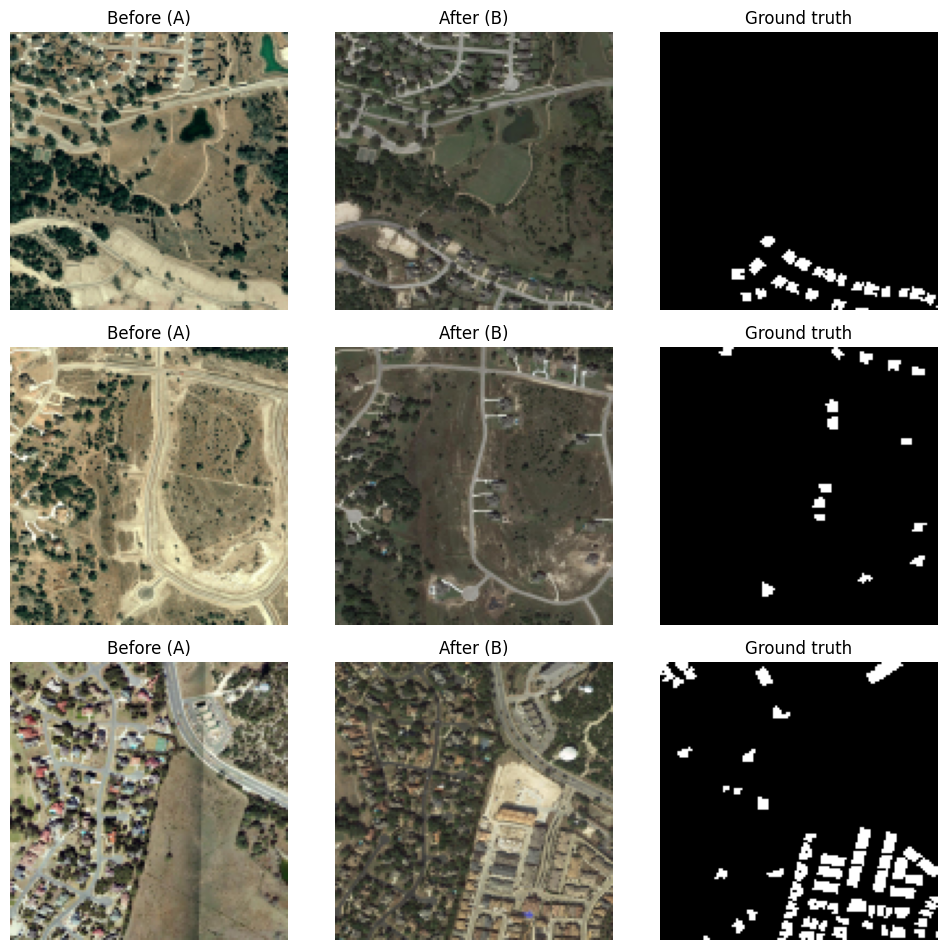

In [5]:
def show_samples(Xa, Xb, Y, n=3):
    n = min(n, len(Xa))
    fig, axes = plt.subplots(n, 3, figsize=(10, 3.2*n))
    if n == 1:
        axes = np.expand_dims(axes, axis=0)
    for i in range(n):
        axes[i, 0].imshow(Xa[i])
        axes[i, 0].set_title("Before (A)")
        axes[i, 1].imshow(Xb[i])
        axes[i, 1].set_title("After (B)")
        axes[i, 2].imshow(Y[i, ..., 0], cmap="gray", vmin=0, vmax=1)
        axes[i, 2].set_title("Ground truth")
        for ax in axes[i]:
            ax.axis("off")
    plt.tight_layout()
    plt.show()

show_samples(X1_train, X2_train, y_train, n=3)

## 6. Prepare the TensorFlow datasets

The training pipeline applies the same spatial transformations to both dates and the label mask. Brightness changes, where enabled, are shared by the two dates. Validation and test samples are not augmented.

In [6]:
AUTOTUNE = tf.data.AUTOTUNE

def preprocess_resnet_pair(image_a, image_b):
    # Inputs are RGB float tensors in the original 0..255 scale.
    image_a = tf.keras.applications.resnet50.preprocess_input(
        tf.cast(image_a, tf.float32)
    )
    image_b = tf.keras.applications.resnet50.preprocess_input(
        tf.cast(image_b, tf.float32)
    )
    return (image_a, image_b)

def augment_pair_tf(image_a, image_b, mask):
    # Cast images to float32 to perform brightness modifications safely
    image_a = tf.cast(image_a, tf.float32)
    image_b = tf.cast(image_b, tf.float32)
    mask = tf.cast(mask, tf.float32)

    # Synchronized horizontal and vertical flips.
    do_flip_lr = tf.random.uniform(()) > 0.5
    image_a = tf.cond(do_flip_lr, lambda: tf.image.flip_left_right(image_a), lambda: image_a)
    image_b = tf.cond(do_flip_lr, lambda: tf.image.flip_left_right(image_b), lambda: image_b)
    mask = tf.cond(do_flip_lr, lambda: tf.image.flip_left_right(mask), lambda: mask)

    do_flip_ud = tf.random.uniform(()) > 0.5
    image_a = tf.cond(do_flip_ud, lambda: tf.image.flip_up_down(image_a), lambda: image_a)
    image_b = tf.cond(do_flip_ud, lambda: tf.image.flip_up_down(image_b), lambda: image_b)
    mask = tf.cond(do_flip_ud, lambda: tf.image.flip_up_down(mask), lambda: mask)

    # Synchronized rotation by 0, 90, 180 or 270 degrees.
    k = tf.random.uniform((), minval=0, maxval=4, dtype=tf.int32)
    image_a = tf.image.rot90(image_a, k)
    image_b = tf.image.rot90(image_b, k)
    mask = tf.image.rot90(mask, k)

    # Same brightness multiplier for both dates.
    brightness_factor = tf.random.uniform((), 0.8, 1.2)
    image_a = tf.clip_by_value(image_a * brightness_factor, 0.0, 255.0)
    image_b = tf.clip_by_value(image_b * brightness_factor, 0.0, 255.0)

    return image_a, image_b, mask

def make_dataset(Xa, Xb, Y, training=False):
    ds = tf.data.Dataset.from_tensor_slices((Xa, Xb, Y))
    if training:
        ds = ds.shuffle(
            buffer_size=len(Xa),
            seed=SEED,
            reshuffle_each_iteration=True
        )
        ds = ds.map(augment_pair_tf, num_parallel_calls=AUTOTUNE)

    ds = ds.map(
        lambda a, b, y: (preprocess_resnet_pair(a, b), y),
        num_parallel_calls=AUTOTUNE
    )
    ds = ds.batch(BATCH_SIZE, drop_remainder=False)
    if not training:
        ds = ds.cache()
    return ds.prefetch(AUTOTUNE)

train_ds = make_dataset(X1_train, X2_train, y_train, training=True)
val_ds = make_dataset(X1_val, X2_val, y_val, training=False)

print("Training batches:", tf.data.experimental.cardinality(train_ds).numpy())
print("Validation batches:", tf.data.experimental.cardinality(val_ds).numpy())

Training batches: 112
Validation batches: 16


## 7. Build M4: unchanged M2 enhanced-temporal-fusion Siamese U-Net

The architecture is deliberately identical to M2:
- Shared ImageNet-pretrained ResNet50 encoder.
- Multi-scale temporal fusion: concatenate feature A, feature B and `abs(A - B)`.
- 1×1 Conv + Batch Normalization + ReLU projection to 32/64/128/256 channels.
- Same U-Net decoder and sigmoid change-probability output.

**No CBAM or other attention module is used in M4.** The experiment isolates the effect of the loss-function change.


In [7]:
@tf.keras.utils.register_keras_serializable()
class AbsoluteDifference(layers.Layer):
    def call(self, inputs):
        return tf.abs(inputs[0] - inputs[1])

def project_temporal_features(feature_a, feature_b, scale_name, output_channels):
    """
    Fuse both temporal features and their absolute difference, then
    project the concatenated channels to a compact representation.
    """
    difference = AbsoluteDifference(name=f"{scale_name}_absolute_difference")(
        [feature_a, feature_b]
    )
    combined = layers.Concatenate(name=f"{scale_name}_temporal_concat")(
        [feature_a, feature_b, difference]
    )
    projected = layers.Conv2D(
        output_channels,
        kernel_size=1,
        padding="same",
        use_bias=False,
        name=f"{scale_name}_fusion_projection"
    )(combined)
    projected = layers.BatchNormalization(
        name=f"{scale_name}_fusion_bn"
    )(projected)
    projected = layers.Activation(
        "relu", name=f"{scale_name}_fusion_relu"
    )(projected)
    return projected

def build_m4_siamese_unet(input_shape=(IMG_SIZE, IMG_SIZE, 3)):
    input_a = layers.Input(shape=input_shape, name="image_before")
    input_b = layers.Input(shape=input_shape, name="image_after")

    resnet = tf.keras.applications.ResNet50(
        weights="imagenet",
        include_top=False,
        input_shape=input_shape
    )

    feature_layer_names = [
        "conv1_relu",          # 64 x 64 x 64
        "conv2_block3_out",    # 32 x 32 x 256
        "conv3_block4_out",    # 16 x 16 x 512
        "conv4_block6_out"     # 8 x 8 x 1024
    ]

    encoder = tf.keras.Model(
        inputs=resnet.input,
        outputs=[resnet.get_layer(name).output for name in feature_layer_names],
        name="shared_resnet50_encoder"
    )
    encoder.trainable = False

    features_a = encoder(input_a)
    features_b = encoder(input_b)

    # Projected fusion channels, shallow to deep.
    projection_channels = [32, 64, 128, 256]
    scale_names = ["scale_64", "scale_32", "scale_16", "scale_8"]

    fused_features = [
        project_temporal_features(fa, fb, name, channels)
        for fa, fb, name, channels in zip(
            features_a, features_b, scale_names, projection_channels
        )
    ]

    # Decoder: 8 -> 16 -> 32 -> 64 -> 128.
    # M2 uses compact projected fusion maps as multi-scale skip features.
    x = fused_features[3]  # 8 x 8 x 256

    x = layers.UpSampling2D(interpolation="nearest", name="up_to_16")(x)
    x = layers.Concatenate(name="decoder_concat_16")([x, fused_features[2]])
    x = layers.Conv2D(256, 3, padding="same", activation="relu",
                      name="decoder_conv_16")(x)

    x = layers.UpSampling2D(interpolation="nearest", name="up_to_32")(x)
    x = layers.Concatenate(name="decoder_concat_32")([x, fused_features[1]])
    x = layers.Conv2D(128, 3, padding="same", activation="relu",
                      name="decoder_conv_32")(x)

    x = layers.UpSampling2D(interpolation="nearest", name="up_to_64")(x)
    x = layers.Concatenate(name="decoder_concat_64")([x, fused_features[0]])
    x = layers.Conv2D(64, 3, padding="same", activation="relu",
                      name="decoder_conv_64")(x)

    x = layers.UpSampling2D(interpolation="nearest", name="up_to_128")(x)
    x = layers.Conv2D(32, 3, padding="same", activation="relu",
                      name="decoder_conv_128")(x)

    output = layers.Conv2D(
        1, 1, activation="sigmoid", dtype="float32",
        name="change_probability"
    )(x)

    model = models.Model(
        [input_a, input_b], output,
        name="M4_Focal_Tversky_M2_Siamese_UNet"
    )
    return model, encoder

model, encoder = build_m4_siamese_unet()
model.summary()

print("\nM4 (unchanged M2) fusion projection outputs:")
for layer_name in [
    "scale_64_fusion_relu",
    "scale_32_fusion_relu",
    "scale_16_fusion_relu",
    "scale_8_fusion_relu"
]:
    print(layer_name, model.get_layer(layer_name).output.shape)

94765736/94765736 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Model: "M4_Focal_Tversky_M2_Siamese_UNet"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ image_before        │ (None, 128, 128,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ image_after         │ (None, 128, 128,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ shared_resnet50_en… │ [(None, 64, 64,   │  8,589,184 │ image_before[0][… │
│ (Functional)        │ 64), (None, 32,   │            │ image_after[0][0] │
│                     │ 32, 256), (None,  │            │                   │
│                     │ 16, 16, 512),     │            │                   │
│                     │ (None, 8, 8,      │            │                   │
│                     │ 1024)]            │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ scale_8_absolute_d… │ (None, 8, 8,      │          0 │ shared_resnet50_… │
│ (AbsoluteDifferenc… │ 1024)             │            │ shared_resnet50_… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ scale_8_temporal_c… │ (None, 8, 8,      │          0 │ shared_resnet50_… │
│ (Concatenate)       │ 3072)             │            │ shared_resnet50_… │
│                     │                   │            │ scale_8_absolute… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ scale_16_absolute_… │ (None, 16, 16,    │          0 │ shared_resnet50_… │
│ (AbsoluteDifferenc… │ 512)              │            │ shared_resnet50_… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ scale_8_fusion_pro… │ (None, 8, 8, 256) │    786,432 │ scale_8_temporal… │
│ (Conv2D)            │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ scale_16_temporal_… │ (None, 16, 16,    │          0 │ shared_resnet50_… │
│ (Concatenate)       │ 1536)             │            │ shared_resnet50_… │
│                     │                   │            │ scale_16_absolut… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ scale_8_fusion_bn   │ (None, 8, 8, 256) │      1,024 │ scale_8_fusion_p… │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ scale_16_fusion_pr… │ (None, 16, 16,    │    196,608 │ scale_16_tempora… │
│ (Conv2D)            │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ scale_8_fusion_relu │ (None, 8, 8, 256) │          0 │ scale_8_fusion_b… │
│ (Activation)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ scale_16_fusion_bn  │ (None, 16, 16,    │        512 │ scale_16_fusion_… │
│ (BatchNormalizatio… │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ scale_32_absolute_… │ (None, 32, 32,    │          0 │ shared_resnet50_… │
│ (AbsoluteDifferenc… │ 256)              │            │ shared_resnet50_… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ up_to_16            │ (None, 16, 16,    │          0 │ scale_8_fusion_r… │
│ (UpSampling2D)      │ 256)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ scale_16_fusion_re… │ (None, 16, 16,    │          0 │ scale_16_fusion_

 Total params: 10,993,921 (41.94 MB)

 Trainable params: 2,403,777 (9.17 MB)

 Non-trainable params: 8,590,144 (32.77 MB)


M4 (unchanged M2) fusion projection outputs:
scale_64_fusion_relu (None, 64, 64, 32)
scale_32_fusion_relu (None, 32, 32, 64)
scale_16_fusion_relu (None, 16, 16, 128)
scale_8_fusion_relu (None, 8, 8, 256)


## 8. Loss function and metrics

This section defines the training loss and the metrics used to monitor segmentation performance. The reported test metrics are calculated separately using the validation-selected probability threshold.

In [8]:
# Explicit convention:
# alpha weights FALSE POSITIVES; beta weights FALSE NEGATIVES.
FOCAL_TVERSKY_ALPHA = 0.6
FOCAL_TVERSKY_BETA = 0.4
FOCAL_TVERSKY_GAMMA = 1.33
FOCAL_TVERSKY_SMOOTH = 1e-6

@tf.keras.utils.register_keras_serializable(package="LEVIR_CD")
def focal_tversky_loss(
    y_true,
    y_pred,
    alpha=FOCAL_TVERSKY_ALPHA,
    beta=FOCAL_TVERSKY_BETA,
    gamma=FOCAL_TVERSKY_GAMMA,
    smooth=FOCAL_TVERSKY_SMOOTH
):
    'Focal Tversky loss; alpha weights FP and beta weights FN.'
    y_true = tf.cast(y_true, tf.float32)
    y_pred = tf.cast(y_pred, tf.float32)
    y_pred = tf.clip_by_value(y_pred, 1e-7, 1.0 - 1e-7)

    # Per-image statistics: reduce over H, W and C, not over the batch.
    axes = [1, 2, 3]
    true_positive = tf.reduce_sum(y_true * y_pred, axis=axes)
    false_positive = tf.reduce_sum((1.0 - y_true) * y_pred, axis=axes)
    false_negative = tf.reduce_sum(y_true * (1.0 - y_pred), axis=axes)

    tversky_index = (
        true_positive + smooth
    ) / (
        true_positive
        + alpha * false_positive
        + beta * false_negative
        + smooth
    )

    per_image_loss = tf.pow(
        tf.maximum(1.0 - tversky_index, 0.0),
        gamma
    )
    return tf.reduce_mean(per_image_loss)


def compile_model(model, learning_rate):
    # Keep optimizer, learning rates and metrics identical to M2.
    model.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=learning_rate),
        loss=focal_tversky_loss,
        metrics=[
            tf.keras.metrics.BinaryAccuracy(name="binary_accuracy", threshold=0.5),
            tf.keras.metrics.Precision(name="precision", thresholds=0.5),
            tf.keras.metrics.Recall(name="recall", thresholds=0.5),
            tf.keras.metrics.BinaryIoU(
                target_class_ids=[1], threshold=0.5, name="change_iou"
            )
        ]
    )

compile_model(model, learning_rate=1e-4)

print(
    "M4 Focal Tversky settings:",
    f"alpha(FP)={FOCAL_TVERSKY_ALPHA},",
    f"beta(FN)={FOCAL_TVERSKY_BETA},",
    f"gamma={FOCAL_TVERSKY_GAMMA},",
    f"smooth={FOCAL_TVERSKY_SMOOTH}"
)


M4 Focal Tversky settings: alpha(FP)=0.6, beta(FN)=0.4, gamma=1.33, smooth=1e-06


## 9. Stage 1 — train the decoder

The encoder is frozen during the first stage, while the decoder and fusion layers are trained. The best checkpoint is selected using validation loss.

In [9]:
STAGE1_EPOCHS = 8
stage1_weights = "/content/m4_checkpoints/m4_stage1_best.weights.h5"

stage1_callbacks = [
    tf.keras.callbacks.ModelCheckpoint(
        stage1_weights,
        monitor="val_loss",
        save_best_only=True,
        save_weights_only=True,
        mode="min",
        verbose=1
    ),
    tf.keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.5,
        patience=3,
        min_lr=1e-7,
        verbose=1
    ),
    tf.keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=6,
        restore_best_weights=True,
        verbose=1
    )
]

history_stage1 = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=STAGE1_EPOCHS,
    callbacks=stage1_callbacks,
    verbose=1
)

model.load_weights(stage1_weights)
print("Restored best Stage 1 weights.")

Epoch 1/8
112/112 ━━━━━━━━━━━━━━━━━━━━ 0s 154ms/step - binary_accuracy: 0.7258 - change_iou: 0.1038 - loss: 0.8257 - precision: 0.1117 - recall: 0.6210
Epoch 1: val_loss improved from None to 0.74302, saving model to /content/m4_checkpoints/m4_stage1_best.weights.h5

Epoch 1: finished saving model to /content/m4_checkpoints/m4_stage1_best.weights.h5
112/112 ━━━━━━━━━━━━━━━━━━━━ 59s 237ms/step - binary_accuracy: 0.8320 - change_iou: 0.1457 - loss: 0.7812 - precision: 0.1598 - recall: 0.6237 - val_binary_accuracy: 0.8716 - val_change_iou: 0.2084 - val_loss: 0.7430 - val_precision: 0.2196 - val_recall: 0.8040 - learning_rate: 1.0000e-04
Epoch 2/8
111/112 ━━━━━━━━━━━━━━━━━━━━ 0s 29ms/step - binary_accuracy: 0.8851 - change_iou: 0.2163 - loss: 0.7127 - precision: 0.2499 - recall: 0.6271
Epoch 2: val_loss improved from 0.74302 to 0.68499, saving model to /content/m4_checkpoints/m4_stage1_best.weights.h5

Epoch 2: finished saving model to /content/m4_checkpoints/m4_stage1_best.weights.h5
112/

## 10. Stage 2 — fine-tune the encoder

The selected convolutional layers in the final ResNet50 stage are unfrozen for fine-tuning. Batch Normalization layers remain frozen, and a lower learning rate is used for this stage.

In [10]:
# Unfreeze only convolutional layers in the ResNet conv4 stage.
encoder.trainable = True
for layer in encoder.layers:
    if layer.name.startswith("conv4_") and not isinstance(
        layer, tf.keras.layers.BatchNormalization
    ):
        layer.trainable = True
    else:
        layer.trainable = False

trainable_encoder_layers = [
    layer.name for layer in encoder.layers if layer.trainable
]
print("Trainable encoder layers:", len(trainable_encoder_layers))
print(trainable_encoder_layers[:10])

# Recompile after changing trainable flags.
compile_model(model, learning_rate=1e-5)

STAGE2_EPOCHS = 40
stage2_weights = "/content/m4_checkpoints/m4_stage2_best.weights.h5"

stage2_callbacks = [
    tf.keras.callbacks.ModelCheckpoint(
        stage2_weights,
        monitor="val_loss",
        save_best_only=True,
        save_weights_only=True,
        mode="min",
        verbose=1
    ),
    tf.keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.5,
        patience=3,
        min_lr=1e-7,
        verbose=1
    ),
    tf.keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=8,
        restore_best_weights=True,
        verbose=1
    )
]

history_stage2 = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=STAGE2_EPOCHS,
    callbacks=stage2_callbacks,
    verbose=1
)

model.load_weights(stage2_weights)
print("Restored best Stage 2 weights.")

Trainable encoder layers: 43
['conv4_block1_1_conv', 'conv4_block1_1_relu', 'conv4_block1_2_conv', 'conv4_block1_2_relu', 'conv4_block1_0_conv', 'conv4_block1_3_conv', 'conv4_block1_add', 'conv4_block1_out', 'conv4_block2_1_conv', 'conv4_block2_1_relu']
Epoch 1/40
112/112 ━━━━━━━━━━━━━━━━━━━━ 0s 161ms/step - binary_accuracy: 0.9608 - change_iou: 0.3753 - loss: 0.5069 - precision: 0.5392 - recall: 0.5533
Epoch 1: val_loss improved from None to 0.57045, saving model to /content/m4_checkpoints/m4_stage2_best.weights.h5

Epoch 1: finished saving model to /content/m4_checkpoints/m4_stage2_best.weights.h5
112/112 ━━━━━━━━━━━━━━━━━━━━ 56s 231ms/step - binary_accuracy: 0.9569 - change_iou: 0.3763 - loss: 0.5063 - precision: 0.5293 - recall: 0.5655 - val_binary_accuracy: 0.9616 - val_change_iou: 0.3864 - val_loss: 0.5704 - val_precision: 0.5408 - val_recall: 0.5751 - learning_rate: 1.0000e-05
Epoch 2/40
111/112 ━━━━━━━━━━━━━━━━━━━━ 0s 42ms/step - binary_accuracy: 0.9538 - change_iou: 0.3750 - l

## 11. Select the checkpoint using validation data

Stage 1 and Stage 2 checkpoints are compared on the validation set. The checkpoint with the lower validation loss is retained for threshold selection and final evaluation.

In [11]:
# Evaluate Stage 2 checkpoint.
model.load_weights(stage2_weights)
stage2_val_loss = float(model.evaluate(val_ds, verbose=0)[0])

# Evaluate Stage 1 checkpoint.
model.load_weights(stage1_weights)
stage1_val_loss = float(model.evaluate(val_ds, verbose=0)[0])

if stage2_val_loss <= stage1_val_loss:
    model.load_weights(stage2_weights)
    selected_stage = "Stage 2 (fine-tuned encoder)"
    selected_val_loss = stage2_val_loss
else:
    model.load_weights(stage1_weights)
    selected_stage = "Stage 1 (frozen encoder)"
    selected_val_loss = stage1_val_loss

print("Stage 1 validation loss:", stage1_val_loss)
print("Stage 2 validation loss:", stage2_val_loss)
print("Selected checkpoint:", selected_stage)
print("Selected validation loss:", selected_val_loss)

FINAL_MODEL_PATH = "/content/m4_checkpoints/M4_FocalTversky_M2_Siamese_UNet.keras"
model.save(FINAL_MODEL_PATH)
print("Saved model:", FINAL_MODEL_PATH)

/usr/local/lib/python3.13/dist-packages/keras/src/saving/saving_lib.py:797: UserWarning: Skipping variable loading for optimizer 'adam', because it has 122 variables whereas the saved optimizer has 46 variables. 
  saveable.load_own_variables(weights_store.get(inner_path))


Stage 1 validation loss: 0.5791696906089783
Stage 2 validation loss: 0.5557848811149597
Selected checkpoint: Stage 2 (fine-tuned encoder)
Selected validation loss: 0.5557848811149597
Saved model: /content/m4_checkpoints/M4_FocalTversky_M2_Siamese_UNet.keras


## 12. Training history

The plots show the training and validation curves for each stage. They provide a view of convergence and any gap between training and validation performance.

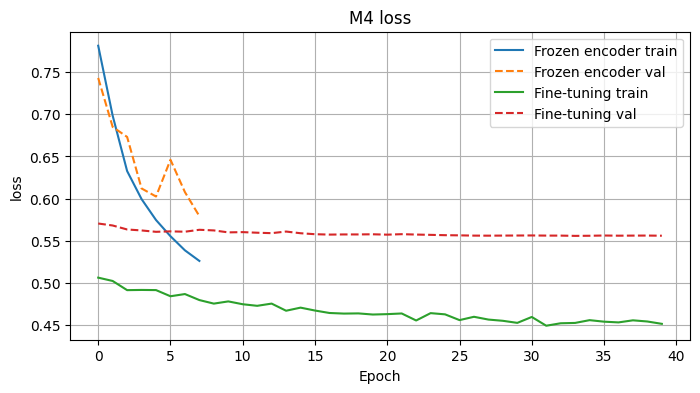

In [12]:
def plot_histories(*histories, labels=None, metric="loss"):
    plt.figure(figsize=(8, 4))
    for i, hist in enumerate(histories):
        label = labels[i] if labels else f"Stage {i+1}"
        if metric in hist.history:
            plt.plot(hist.history[metric], label=f"{label} train")
        val_key = "val_" + metric
        if val_key in hist.history:
            plt.plot(hist.history[val_key], linestyle="--", label=f"{label} val")
    plt.xlabel("Epoch")
    plt.ylabel(metric)
    plt.title(f"M4 {metric}")
    plt.legend()
    plt.grid(True)
    plt.show()

plot_histories(history_stage1, history_stage2,
               labels=["Frozen encoder", "Fine-tuning"], metric="loss")

## 13. Choose the probability threshold on validation data

The threshold is selected from validation predictions using the predefined threshold grid and F1 score. The selected value is then fixed before the test set is evaluated.

In [13]:
def predict_dataset(model, dataset):
    return model.predict(dataset, verbose=1)

val_probs = predict_dataset(model, val_ds)

def binary_metrics(y_true, y_prob, threshold=0.5):
    y_true = np.asarray(y_true).astype(np.uint8).reshape(-1)
    y_pred = (np.asarray(y_prob).reshape(-1) >= threshold).astype(np.uint8)

    tn, fp, fn, tp = confusion_matrix(
        y_true, y_pred, labels=[0, 1]
    ).ravel()

    accuracy = (tp + tn) / max(tp + tn + fp + fn, 1)
    precision = tp / max(tp + fp, 1)
    recall = tp / max(tp + fn, 1)
    f1 = 2 * precision * recall / max(precision + recall, 1e-12)
    iou = tp / max(tp + fp + fn, 1)
    dice = 2 * tp / max(2 * tp + fp + fn, 1)

    return {
        "threshold": float(threshold),
        "accuracy": accuracy,
        "precision": precision,
        "recall": recall,
        "f1": f1,
        "iou": iou,
        "dice": dice,
        "tp": int(tp), "fp": int(fp), "fn": int(fn), "tn": int(tn)
    }

thresholds = np.arange(0.05, 0.96, 0.05)
val_rows = [
    binary_metrics(y_val, val_probs, threshold=t)
    for t in thresholds
]
val_threshold_table = pd.DataFrame(val_rows)
display(val_threshold_table)

best_idx = val_threshold_table["f1"].idxmax()
BEST_THRESHOLD = float(val_threshold_table.loc[best_idx, "threshold"])
print("Selected validation threshold:", BEST_THRESHOLD)
print("Validation metrics at selected threshold:")
display(pd.DataFrame([val_rows[best_idx]]))

16/16 ━━━━━━━━━━━━━━━━━━━━ 6s 24ms/step


,threshold,accuracy,precision,recall,f1,iou,dice,tp,fp,fn,tn
0,0.05,0.956264,0.485971,0.692859,0.571260,0.399835,0.571260,30553,32317,13544,972162
1,0.10,0.958367,0.503775,0.668730,0.574649,0.403164,0.574649,29489,29047,14608,975432
2,0.15,0.959540,0.514934,0.653673,0.576068,0.404561,0.576068,28825,27153,15272,977326
3,0.20,0.960338,0.523183,0.641767,0.576439,0.404928,0.576439,28300,25792,15797,978687
4,0.25,0.960938,0.529810,0.632379,0.576568,0.405055,0.576568,27886,24748,16211,979731
5,0.30,0.961450,0.535771,0.623943,0.576505,0.404993,0.576505,27514,23840,16583,980639
6,0.35,0.961802,0.540239,0.615461,0.575402,0.403905,0.575402,27140,23097,16957,981382
7,0.40,0.962230,0.545723,0.607910,0.575140,0.403647,0.575140,26807,22315,17290,982164
8,0.45,0.962593,0.550702,0.600132,0.574355,0.402874,0.574355,26464,21591,17633,982888
9,0.50,0.962895,0.555147,0.592399,0.573168,0.401707,0.573168,26123,20933,17974,983546


Selected validation threshold: 0.25
Validation metrics at selected threshold:


,threshold,accuracy,precision,recall,f1,iou,dice,tp,fp,fn,tn
0,0.25,0.960938,0.52981,0.632379,0.576568,0.405055,0.576568,27886,24748,16211,979731


## 14. Evaluate on the held-out test set

The selected checkpoint and fixed threshold are applied to the test split. These results are the final evaluation for this run; the test labels are not used to adjust model settings.

In [14]:
X1_test, X2_test, y_test = load_split(test_pairs, "test")
test_ds = make_dataset(X1_test, X2_test, y_test, training=False)

test_probs = predict_dataset(model, test_ds)
test_results = binary_metrics(y_test, test_probs, threshold=BEST_THRESHOLD)

print("M4 FINAL TEST RESULTS")
display(pd.DataFrame([test_results]))

test: A=(128, 128, 128, 3), B=(128, 128, 128, 3), mask=(128, 128, 128, 1), mask values=[0. 1.]
32/32 ━━━━━━━━━━━━━━━━━━━━ 1s 25ms/step
M4 FINAL TEST RESULTS


,threshold,accuracy,precision,recall,f1,iou,dice,tp,fp,fn,tn
0,0.25,0.95127,0.517533,0.627506,0.567239,0.395906,0.567239,66975,62437,39757,1927983


## 15. Inspect predicted change masks

The visualizations compare the input images, reference mask and model prediction. They are included to complement the numerical metrics and show examples of missed and incorrectly detected changes.

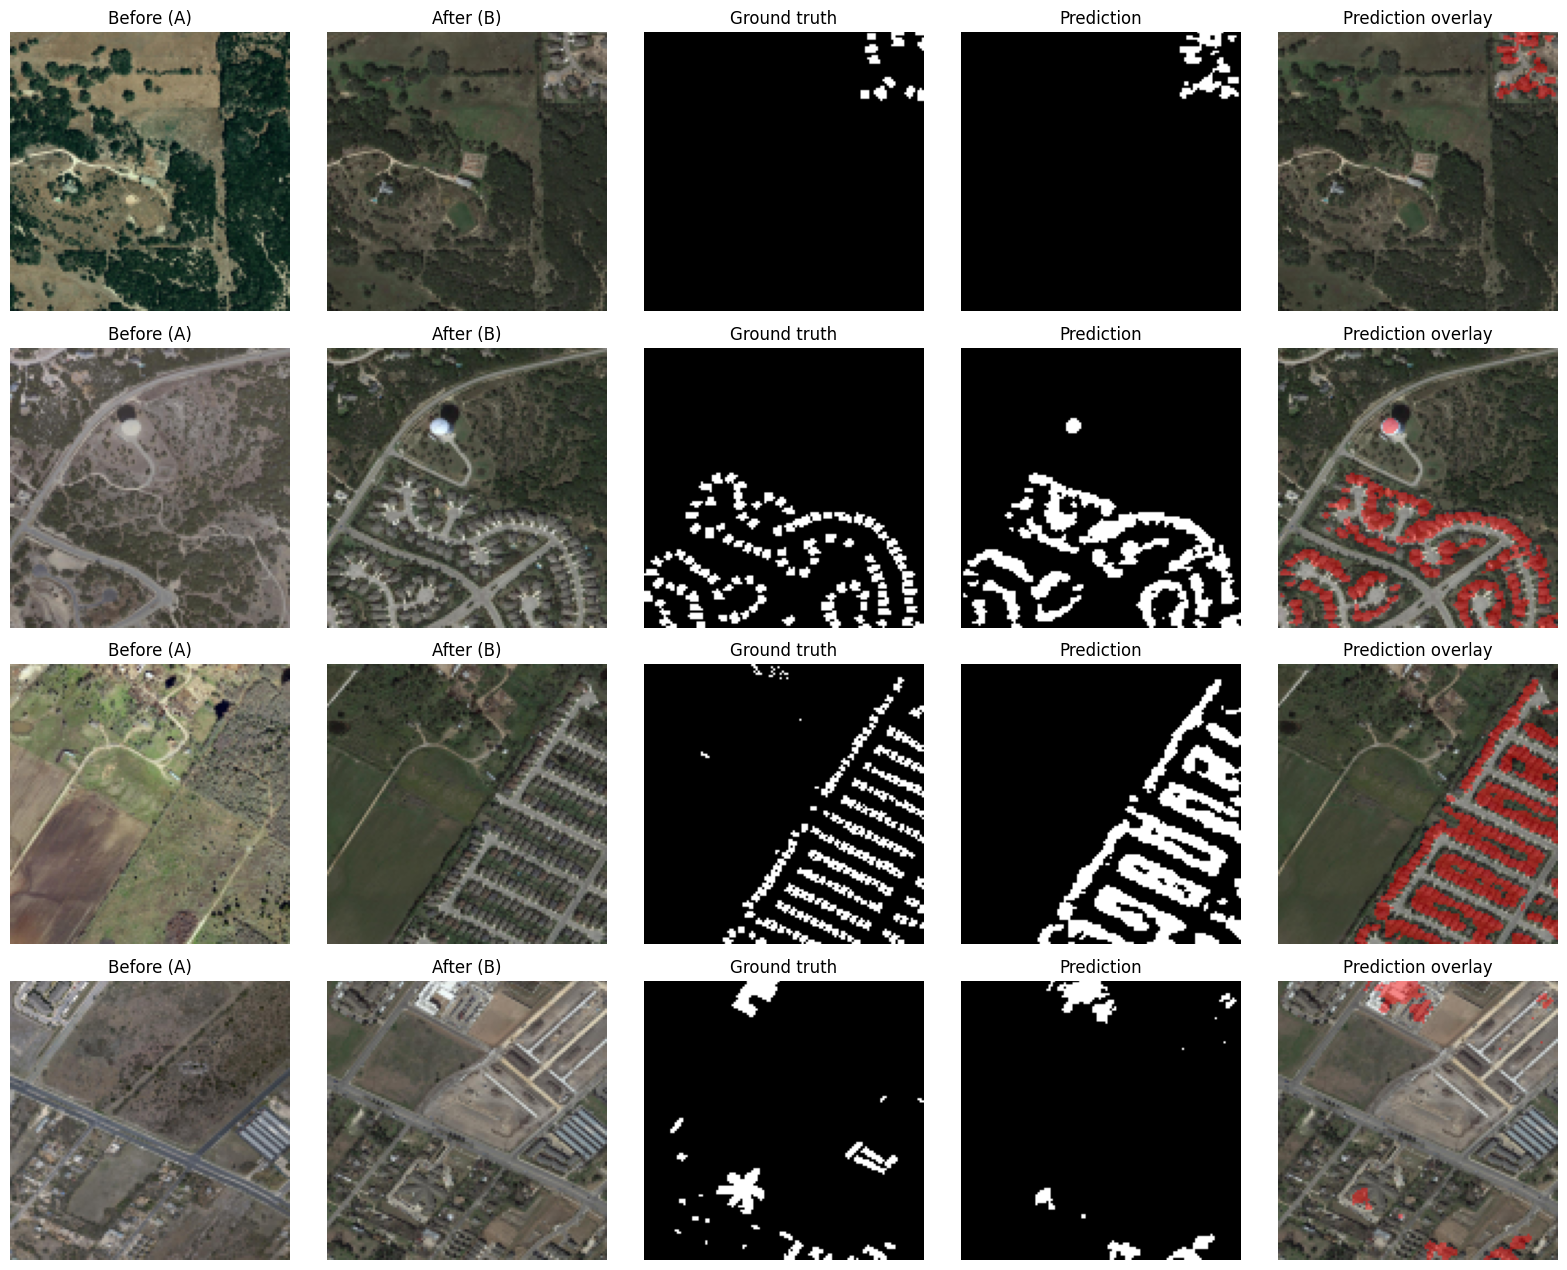

In [15]:
def visualize_predictions(Xa, Xb, Y, probabilities, threshold, indices=None, n=4):
    if indices is None:
        indices = list(range(min(n, len(Xa))))
    fig, axes = plt.subplots(len(indices), 5, figsize=(16, 3.2*len(indices)))
    if len(indices) == 1:
        axes = np.expand_dims(axes, axis=0)

    for row, idx in enumerate(indices):
        pred = (probabilities[idx, ..., 0] >= threshold).astype(np.uint8)
        gt = Y[idx, ..., 0]

        overlay = Xb[idx].copy()
        changed = pred == 1
        # Highlight predicted changes in red.
        overlay[changed] = (
            0.55 * overlay[changed] + 0.45 * np.array([255, 0, 0])
        ).astype(np.uint8)

        panels = [
            (Xa[idx], "Before (A)", None),
            (Xb[idx], "After (B)", None),
            (gt, "Ground truth", "gray"),
            (pred, "Prediction", "gray"),
            (overlay, "Prediction overlay", None)
        ]
        for col, (image, title, cmap) in enumerate(panels):
            axes[row, col].imshow(image, cmap=cmap, vmin=0, vmax=1 if cmap else None)
            axes[row, col].set_title(title)
            axes[row, col].axis("off")

    plt.tight_layout()
    plt.show()

visualize_predictions(
    X1_test, X2_test, y_test, test_probs,
    BEST_THRESHOLD, indices=[0, 1, 2, 3]
)

## 16. Save the model and evaluation results

The final cell saves the trained model and the evaluation files to the experiment-specific Google Drive directory.

In [16]:
import shutil

DRIVE_OUTPUT = "/content/drive/MyDrive/LEVIR-CD_M4_outputs"
os.makedirs(DRIVE_OUTPUT, exist_ok=True)

shutil.copy2(FINAL_MODEL_PATH, os.path.join(DRIVE_OUTPUT, "M4_FocalTversky_M2_Siamese_UNet.keras"))
pd.DataFrame([test_results]).to_csv(
    os.path.join(DRIVE_OUTPUT, "M4_test_metrics.csv"), index=False
)
val_threshold_table.to_csv(
    os.path.join(DRIVE_OUTPUT, "M4_validation_thresholds.csv"), index=False
)

print("Saved M4 model and results to:", DRIVE_OUTPUT)

Saved M4 model and results to: /content/drive/MyDrive/LEVIR-CD_M4_outputs


## Experiment summary

M4 retains the M2 architecture and changes the training objective to Focal Tversky Loss (`alpha=0.6`, `beta=0.4`, `gamma=1.33`). The test results are reported below.

## M2 and M4 comparison

The table uses the saved test-evaluation outputs. M4 changes the loss function while retaining the M2 architecture.

| Model | Loss | Threshold | Test F1 | Test IoU |
|---|---|---:|---:|---:|
| M2 | BCE + Dice | 0.40 | 61.55% | 44.46% |
| M4 | Focal Tversky | 0.25 | 56.72% | 39.59% |

M4 does not improve F1 or IoU in this run. Its precision and recall values, along with the confusion matrix, are available in the evaluation output. The result should be reported as observed rather than changing the loss parameters after examining the test set.